In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Jupyter is working!")

Jupyter is working!


In [48]:
url = "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv"
df = pd.read_csv(url)
df.columns

Index(['model_year', 'origin', 'fuel_type', 'drivetrain', 'num_doors',
       'engine_displacement', 'num_cylinders', 'horsepower', 'vehicle_weight',
       'acceleration', 'fuel_efficiency_mpg'],
      dtype='object')

In [49]:
df_sub = df[['engine_displacement',
'horsepower',
'vehicle_weight',
'model_year',
'fuel_efficiency_mpg']]


<Axes: xlabel='fuel_efficiency_mpg', ylabel='Count'>

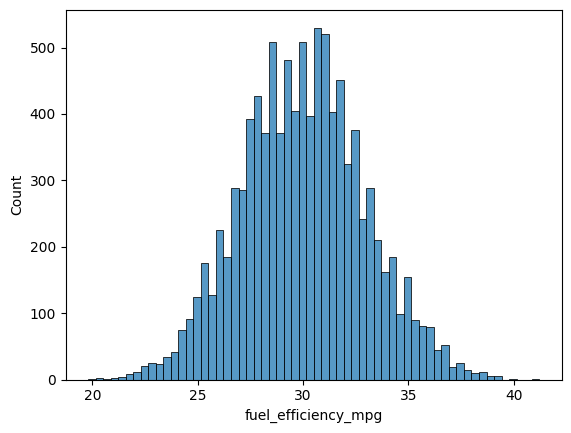

In [50]:
sns.histplot(df_sub['fuel_efficiency_mpg'])

In [51]:
df_sub.isnull().sum()

engine_displacement      0
horsepower             877
vehicle_weight           0
model_year               0
fuel_efficiency_mpg      0
dtype: int64

In [52]:
df_sub['horsepower'].median()

254.0

In [53]:
df_target = df_sub['fuel_efficiency_mpg']
del df_sub['fuel_efficiency_mpg']
df_sub.columns

Index(['engine_displacement', 'horsepower', 'vehicle_weight', 'model_year'], dtype='object')

In [58]:
n = len(df_sub)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed(42)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = df_sub.iloc[idx[:n_train]]
df_val = df_sub.iloc[idx[n_train:n_train + n_val]]
df_test = df_sub.iloc[idx[n_train + n_val:]]

y_train = df_target.iloc[idx[:n_train]]
y_val = df_target.iloc[idx[n_train:n_train + n_val]]
y_test = df_target.iloc[idx[n_train + n_val:]]
df_train.head()

,engine_displacement,horsepower,vehicle_weight,model_year
6252,1900,239.0,3790,2015
4684,2000,224.0,4380,1992
1731,2330,286.0,4090,2022
4742,2300,NaN,4150,1997
4521,2340,269.0,4400,2001


### Fill NaN Values with Zero for Regression

In [59]:
df_train = df_train.fillna(0)
df_test = df_test.fillna(0)
df_val = df_val.fillna(0)
df_train.isnull().sum()

engine_displacement    0
horsepower             0
vehicle_weight         0
model_year             0
dtype: int64

In [64]:
def linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])
    XTX_inv = np.linalg.inv((X.T).dot(X))
    w = XTX_inv.dot(X.T).dot(y)
    return w[0], w[1:]

In [65]:
def rmse(y_predict, y_true):
    return np.sqrt(((y_predict - y_true) ** 2).mean())

In [67]:
X_train = df_train.values
#y_train = y_train.values
w0, w = linear_regression(df_train, y_train)

In [63]:
print(w0, w)

-0.002252671298190064 [ 0.0048971  -0.00432331  0.02624709]


In [68]:
X_val = df_val.values
y_predict = w0 +  X_val.dot(w)
rmse(y_predict, y_val)

2.20529319475358

### Fill NaN Values with Mean for Regression

In [73]:
n = len(df_sub)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed(42)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = df_sub.iloc[idx[:n_train]]
df_val = df_sub.iloc[idx[n_train:n_train + n_val]]
df_test = df_sub.iloc[idx[n_train + n_val:]]

y_train = df_target.iloc[idx[:n_train]]
y_val = df_target.iloc[idx[n_train:n_train + n_val]]
y_test = df_target.iloc[idx[n_train + n_val:]]
df_train.isnull().sum()

engine_displacement      0
horsepower             538
vehicle_weight           0
model_year               0
dtype: int64

In [74]:
mhp = df_train['horsepower'].mean()
df_train = df_train.fillna(mhp)
df_test = df_test.fillna(mhp)
df_val = df_val.fillna(mhp)
df_train.isnull().sum()

engine_displacement    0
horsepower             0
vehicle_weight         0
model_year             0
dtype: int64

In [75]:
X_train = df_train.values
y_train = y_train.values
w0, w = linear_regression(df_train, y_train)

In [76]:
w0, w

(-153.2964563922209,
 array([-0.00102386, -0.00648622, -0.00388828,  0.10197897]))

In [77]:
X_val = df_val.values
y_predict = w0 +  X_val.dot(w)
rmse(y_predict, y_val)

2.2018174845707